# <p style="color:hotpink">**Data Adjustment: Evaluating a Research Design Mismatch**

## Project Background

The original objective of this project was to investigate whetther data-driven interventions could reduce maternal telehealth appointment no-show rates from approximately 20% to a target of 3-5%.

However, exploratory data analysis revealed an unexpected finding: the original synthetic dataset already contained a no-show rate of approximately 3.2%.

This presented a methodological challenge. The dataset already reflected the intended improvement target before any interventions had been introduced or evaluated.

## Purpose of This Investigation

Rather than immediately modifying the original data, I investigated whether resampling could establish the higher baseline required by my initial research design.

This notebook documents four stages:

1. Identify the discrepancy between the research objective and the original dataset.
2. Validate the original distribution and examine the results of experimental resampling.
3. Determine whether adjusting the dataset is justified.
4. Document the final methodological decision and its implications for subsequent analysis.

The objective is not simply to achieve a desired distribution, but to evaluate whether the adjustment produces a defensible dataset for the research question.

In [1]:
import pandas as pd
import numpy as np
from sklearn.utils import resample
import matplotlib.pyplot as plt
import seaborn as sns

# Load clean dataset
df = pd.read_csv("maternal_telehealth_data_clean.csv")

# Check current distribution
df['status'].value_counts(normalize=True) * 100

status
Show         86.492611
Cancelled     8.837438
No-Show       3.192118
Scheduled     1.477833
Name: proportion, dtype: float64

## <p style="color:hotpink">**Step 1: Validate the Original Distribution**

First, I examined the original appointment outcome distribution to determine whether the dataset aligned with my initial research objective.

The project was designed to investigate reducing a hypothetical 20% no-show rate to approximately 3-5%.

However, the original synthetic dataset already exhibited a no-show rate within that target range.

Before making any adjustments, I needed to validate this discrepancy and determine whether modifying the dataset would be methodologically justified.


In [2]:
# Validate the original appointment distribution

# Count total appointments
total_appointments = len(df)

# Count appointments by outcome
status_counts = df["status"].value_counts()

# Calculate the no-show percentage
no_show_count = status_counts["No-Show"]
no_show_rate = (no_show_count / total_appointments) * 100

# Display validation results
print("Total appointments:", total_appointments)
print("No-show appointments:", no_show_count)
print(f"No-show rate: {no_show_rate:.2f}%")
print("Duplicate records:", df.duplicated().sum())
print("Unique patients IDs:", df["patient_id"].nunique())

Total appointments: 10150
No-show appointments: 324
No-show rate: 3.19%
Duplicate records: 0
Unique patients IDs: 10150


## <p style="color:hotpink">**Step 2: Document the original experimental assumption**

The original research objective was to investigate whether predictive analytics are targeted interventions could reduce maternal telehealth no-show rates from approximately 20% to a target of 3-5%.

However, validation of the original synthetic dataset revealed a baseline no-show rate of only 3.19%.

To investigate the discrepancy, I explored resampling the appointment outcomes to approximate the originally intended 20% no-show baseline.

The experimental distribution was defined as:

- Show: 65%
- No-Show: 20%
- Cancelled: 10%
- Scheduled: 5%

These percentages were selected for experimental purposes and should not be interpreted as verified real-world maternal telhealth benchmarks.

The purpose of this adjustment was to examine whether resampling could support the original research design without compromising the integrity of the dataset.

In [3]:
# Define target distribution
target_distribution = {
    "Show": 0.65,
    "No-Show": 0.20,
    "Cancelled": 0.10,
    "Scheduled": 0.05
}

target_distribution

{'Show': 0.65, 'No-Show': 0.2, 'Cancelled': 0.1, 'Scheduled': 0.05}

## <p style="color:hotpink">**Step 3: Calculate Experimental Sample Sizes**

Using the experimental target distribution established in Step 2, I calculated the number of observations required for each appointment outcome.

The original dataset contains 10,150 appointments. Applying the proposed proportions produces approximately 2, 030 no-show observations, compared with the original 324.

These calculations illustrate the scale of adjustment required to recreate the intended 20% baseline.

The resulting target total is 10,149 observations because integer conversion truncates fractional sample sizes.

Importantly, these calculations define the desired number of records but do not generate new, independent patient observations.

In [4]:
# Resample each outcome category
# Get total desired size
n_total = len(df)

# New sample sizes
new_sizes = {status: int(prop * n_total) for status, prop in target_distribution.items()}
new_sizes

{'Show': 6597, 'No-Show': 2030, 'Cancelled': 1015, 'Scheduled': 507}

## <p style="color:hotpink">**Step 4: Resample Each Category**

Using the `sklearn.utils.resample` function, I experimented with modifying the original appointment outcome distribution.

The procedure:

- Downsamples "Show" appointments.
- Upsamples "No-Show" appointments.
- Upsamples "Cancelled" appointments.
- Upsamples "Scheduled" appointments.

Downsampling selects fewer observations from an existing category, while upsampling with replacement allows existing observations to be selected multiple times.

This approach can achieve the intended numerical distribution without generating new patient information.

However, repeated observations are not independent appointments. Therefore, achieving the target percentages does not necessarily produce a more appropriate dataset for the original research objective.

The following steps evaluate the results before deciding whether the adjustment should be retained.

In [5]:
# Split by category
groups = {status: df[df['status'] == status] for status in df['status'].unique()}

# Resample
balanced_groups = []
for status, group in groups.items():
    desired_size = new_sizes[status]
    if len(group) > desired_size:
        sampled = resample(group, replace=False, n_samples=desired_size, random_state=42)
    else:
        sampled = resample(group, replace=True, n_samples=desired_size, random_state=42)
    balanced_groups.append(sampled)

# Combine into new DataFrame
df_balanced = pd.concat(balanced_groups).sample(frac=1, random_state=42).reset_index(drop=True)

## <p style="color:hotpink">**Step 5: Validate the Experimental Distribution**

After resampling, I evaluated whether the adjusted dataset achieved the intended experimental outcome distribution.

Although the percentages closely match the proposed targets, numerical alignment alone does not establish that the adjusted dataset is suitable for the original research objective.

To evaluate the adjustment, I compared the number of records, unique patient identifiers, and duplicate observations in the original and resampled datasets.

This validation helps determine whether resampling instroduced additional independent patient information or ismply repeated existing observations.

In [6]:
df_balanced['status'].value_counts(normalize=True) * 100

status
Show         65.001478
No-Show      20.001971
Cancelled    10.000985
Scheduled     4.995566
Name: proportion, dtype: float64

In [7]:
# Compare original and resmpled dataset integrity

# Create a comparison table
validation = pd.DataFrame({
    "Dataset": ["Original", "Resampled"],
    "Total Records": [
        len(df),
        len(df_balanced)
    ],
    "Unique Records": [
        len(df.drop_duplicates()),
        len(df_balanced.drop_duplicates())
    ],
    "Duplicate Records": [
        df.duplicated().sum(),
        df_balanced.duplicated().sum()
    ],
    "Unique Patients IDs": [
        df["patient_id"].nunique(),
        df_balanced["patient_id"].nunique()
    ]
})

# Display the comparison
display(validation)

,Dataset,Total Records,Unique Records,Duplicate Records,Unique Patients IDs
0,Original,10150,10150,0,10150
1,Resampled,10149,7653,2496,7653


## <p style="color:hotpink">**Step 6: Visualize the Experimental Distribution**

The following visualization illustrates the outcome distribution produced by the experimental resampling procedure.

The adjusted dataset closely matches the proposed 65% Show, 20% No-Show, 10% Cancelled, and 5% Scheduled distribution.

However, the validation results from Step 5 revealed that the resampled dataset contains 2,496 duplicate observations and only 7,653 unique records.

Although the visualization demonstrates that the numerical adjustment was successful, it does not establish that the adjusted dataset respresents a new, independent patient population.

This distinction is important because the original research objective required a meaningful baseline from which to evaluate potential reductions in appointment no-shows.

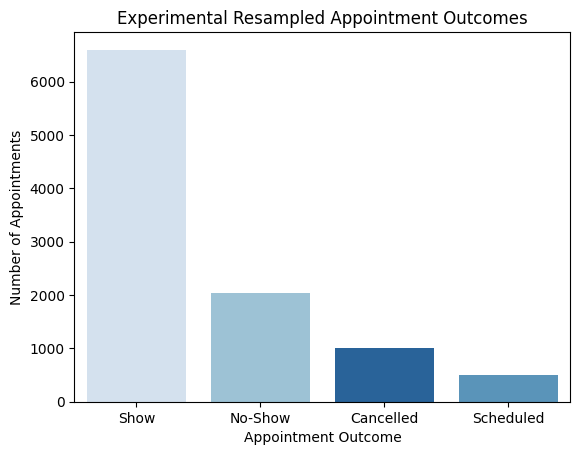

In [8]:
# Visualize the experimental resampled distribution

sns.countplot(
    data=df_balanced,
    x="status",
    hue="status",
    order=df_balanced["status"].value_counts().index,
    palette="Blues",
    legend=False
)

plt.title("Experimental Resampled Appointment Outcomes")
plt.xlabel("Appointment Outcome")
plt.ylabel("Number of Appointments")
plt.show()

## <p style="color:hotpink">**Step 7: Findings and Methodological Decision**

### Summary of Findings

The original objective of this project was to investigate whether predictive analytics and targeted interventions could reduce maternal telehealth appointment no-show rates from approximately 20% to 3-5%.

However, validation of the original synthetic dataset revealed that the no-show rate was already 3.19% before any interventions were applied.

To investigate this discrepancy, I experimented with resampling the dataset to approximate the originally intended 20% no-show baseline.

**The experiment produced the following findings:**

- The original dataset contained 10,150 observations, including 324 no-shows (3.19%).
- The resampled dataset contained 10,149 observations, with approximately 20% classified as no-shows.
- The resampled dataset contained 2,496 duplicate records, leaving only 7,653 unique observations.
- Resampling successfully changed the numerical distribution but did not generate additional independent patient appointments.

### Methodological Decision

Although resampling achieved the intended percentages, it did not resolve the underlying mismatch between the original research objective and the available data.

The resulting dataset repeated existing observations rather than representing a newly simulated population with an independently established 20% no-show baseline.

Using this adjusted dataset to evaluate the effectiveness of interventions could therefore produce misleading conclusions.

**I elected to preserve the original cleaned dataset without changing patient records or appointment outcomes.**

This decision prioritizes data integrity and transparent research practices over forcing the data to conform to the initial hypothesis.

### Implications for Predictive Modeling

The original dataset will serve as the source for the next phase of this project.

Although the no-show class represents only 3.19% of appointments, the dataset can still be used to investigate potential predictors of missed appointments.

The modeling phase will address class imbalance through appropriate training techniques and evaluate performance using metrics suited to minority-class classification.

However, the original objective of demonstrating a reduction from 20% to 3-5% cannot be directly evaluated using this dataset.

### Conclusion and Reflection

This investigation reinforced an important lesson: a dataset must be evaluated against the research question before attempting to modify it.

While the resampling experiment was technically successful, it did not procide a scientifically appropriate solution to the original research-design problem.

Rather than discard the project or artificially alter its outcome, I chose to document the limitation, preserve the original data, and continue with an adjusted analytical objective.

The lessons learned from this investigation subsequently informed my DATA 495 Capstone project, where I designed a new synthetic dataset with an intentionally higher no-show baseline and conducted a more comprehensive predictive modeling analysis.

This progression reflects the importance of validating research assumptions, recognizing methodological limitations, and allowing evidence to guide analytical decisions.